# Cell-type deconvolution of Visium spots with RCTD

We load a pregrown tumor, cut the resected tumor in two, and measure one half by single-cell RNA sequencing (scRNA-seq) and a section of a lesion in the other half by 10x Visium.
We then deconvolve the Visium spots into cell types with RCTD ([Cable et al. 2022](https://github.com/dmcable/spacexr)), using the scRNA-seq data of the same tumor as the reference, and compare its cell-type proportions per spot with the true proportions, which the answer key holds, since `iscc` tracks the cells in each spot.

RCTD runs in its own conda environment, `iscc-rctd`, from a short R script that the notebook writes and runs with that environment's `Rscript`.

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import pandas as pd

import iscc.pregrown
from iscc.data import Visium, scRNA
from iscc.data.human import HumanGenomeLayer, write_scrna, write_visium
from iscc.integrations import biological_types
from iscc.sample import Resection

RSCRIPT = os.path.expanduser("~/miniconda3/envs/iscc-rctd/bin/Rscript")
os.chdir(tempfile.mkdtemp())        # the data and the tool's outputs go to a scratch directory

## The pregrown ductal tumor

We load the pregrown ductal tumor ([`iscc.pregrown.ductal`](https://pedrofale.github.io/iscc/reference/#pregrown-tumors)), the tumor of the paper's regime with 200,284 cancer cells on a field of 1 cm, which have invaded the stroma from several glands while other glands still hold tumors in situ.
Its genome has one segment per chromosome arm ([`arm_genome`](https://pedrofale.github.io/iscc/reference/arm_genome/)), which [`HumanGenomeLayer`](https://pedrofale.github.io/iscc/reference/HumanGenomeLayer/) maps onto the human genome, and the epithelium is its cell of origin, so that cancer cells share the expression baseline of normal epithelial cells and differ from them only by what evolution did to them.

200,284 cancer cells after 299 generations


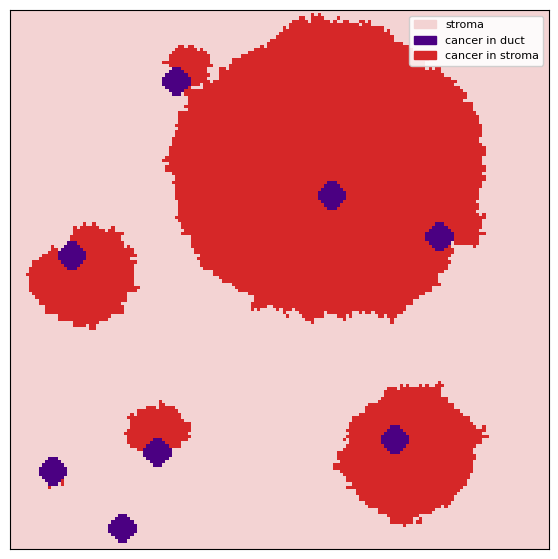

In [2]:
tumor = iscc.pregrown.ductal()
print(f"{tumor.get_cancer_size():,} cancer cells after {tumor.time:.0f} generations")
tumor.plot_tissue();

## Two samples of one resection

[`Resection`](https://pedrofale.github.io/iscc/reference/Resection/) cuts the specimen in the plane into two halves, as a pathologist would, here into the upper and the lower half of the map.
We dissociate the upper half, which holds the largest lesion, into about 3,000 cells for scRNA-seq.
From the lower half we cut a thin section of the lesion in the lower right of the map, a window of 64 by 64 demes around it ([`primary_window`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/)), keeping half of the depth of each deme, so that the section is about one cell layer thick.
The tumor caps every sample at a few thousand cells (`max_cells`), so we raise the cap for the section, letting its thickness set the number of cells.

In [3]:
specimen = Resection(tumor)
upper_half, lower_half = specimen.bisect(frac=0.5, axis="y")
lesion = sorted(set(tumor.primary_window(side=64, center=(140, 128))) & set(lower_half))
cells = specimen.dissociate(upper_half, max_cells=3000)
section = specimen.slice(lesion, depth_frac=0.5, max_cells=100_000, layers="visium")
for name, sample in [("dissociated", cells), ("section", section)]:
    types = pd.Series(biological_types(sample["cell_type"].iloc[:, 0])).value_counts()
    print(f"{name:>12}: {types.sum():,} cells,", types.to_dict())

 dissociated: 3,092 cells, {'cancer': 1654, 'stromal': 1386, 'epithelial': 52}
     section: 31,878 cells, {'stromal': 18208, 'cancer': 13062, 'epithelial': 608}


We measure the section with [`Visium`](https://pedrofale.github.io/iscc/reference/Visium/), with its default spots of 55 µm on a square capture area the size of the section, and the dissociated cells with the 10x Genomics preset of [`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/), both over the human genes.
With `section_frac=1.0`, Visium places the cells of each deme at positions inside it and centers the section on the capture area, without thinning the section again.
[`write_visium`](https://pedrofale.github.io/iscc/reference/write_visium/) and [`write_scrna`](https://pedrofale.github.io/iscc/reference/write_scrna/) write the data as Space Ranger and Cell Ranger output, with the answer key in a separate `truth` folder that no tool reads.

In [4]:
layer = HumanGenomeLayer(tumor)
expression = layer.expression(tumor)
visium = Visium(seed=1, section_frac=1.0).run(section, grid_side=64, gene_lift=expression)
write_visium("visium", visium, layer, tumor=tumor)
rna = scRNA(protocol="10x", n_cells=len(cells["cell_exp"]), seed=1).run(cells, gene_lift=expression)
write_scrna("scrna", rna, layer, cells, tumor=tumor)

in_tissue = visium.obs["n_cells"] > 0
print(f"Visium: {in_tissue.sum():,} spots over the tissue, a median of {visium.obs.loc[in_tissue, 'n_cells'].median():.0f} "
      f"cells and {visium.obs.loc[in_tissue, 'n_counts'].median():,.0f} UMIs per spot")
print(f"scRNA: {rna.obs.shape[0]:,} cells, a median of {rna.obs['n_counts'].median():,.0f} UMIs per cell")

Visium: 1,131 spots over the tissue, a median of 5 cells and 16,674 UMIs per spot
scRNA: 3,092 cells, a median of 3,512 UMIs per cell


RCTD needs the cell type of each reference cell.
A user annotates the microenvironment from marker genes and tells cancer cells from normal epithelial cells by copy number, for example with inferCNV as in [the scRNA copy-number tutorial](tool_scrna_cnv.ipynb).
Here we take the cell types from the answer key, which stands for an annotation without errors, and leave out the doublets.

In [5]:
cell_truth = pd.read_csv("scrna/truth/cells.tsv", sep="\t", index_col="barcode", dtype={"genotype": str})
cell_truth["cell_type"] = biological_types(cell_truth["genotype"])
cell_truth.loc[~cell_truth["is_doublet"], ["cell_type"]].to_csv("reference_cell_types.csv")
cell_truth.loc[~cell_truth["is_doublet"], "cell_type"].value_counts().to_dict()

{'cancer': 1566, 'stromal': 1323, 'epithelial': 48}

## RCTD

The script below runs spacexr's standard workflow, which builds a `Reference` from the annotated scRNA-seq counts and a `SpatialRNA` from the Visium counts and the spot positions, and runs `run.RCTD`.
RCTD runs in full mode, which fits any mixture of cell types in a spot, as spacexr's documentation recommends for technologies with large spots such as Visium.
It runs on one core (`max_cores = 1`), since its parallel workers failed intermittently on our laptop and one core is about as fast at this size, and every other setting is the default.
The counts are read from the Cell Ranger and Space Ranger matrix directories with the Matrix package.

In [6]:
%%writefile run_rctd.R
suppressMessages({library(spacexr); library(Matrix)})

read_10x <- function(dir) {           # a filtered_feature_bc_matrix directory of Cell Ranger or Space Ranger
  counts <- readMM(file.path(dir, "matrix.mtx.gz"))
  rownames(counts) <- make.unique(read.delim(file.path(dir, "features.tsv.gz"), header = FALSE)[[2]])
  colnames(counts) <- read.delim(file.path(dir, "barcodes.tsv.gz"), header = FALSE)[[1]]
  as(counts, "CsparseMatrix")
}

ref_counts <- read_10x("scrna/outs/filtered_feature_bc_matrix")
annotation <- read.csv("reference_cell_types.csv", row.names = 1)
ref_counts <- ref_counts[, rownames(annotation)]
cell_types <- factor(annotation$cell_type, levels = sort(unique(annotation$cell_type)))
names(cell_types) <- rownames(annotation)
reference <- Reference(ref_counts, cell_types)

spot_counts <- read_10x("visium/outs/filtered_feature_bc_matrix")
positions <- read.csv("visium/outs/spatial/tissue_positions.csv", row.names = 1)
coords <- positions[colnames(spot_counts), c("pxl_col_in_fullres", "pxl_row_in_fullres")]
colnames(coords) <- c("x", "y")
puck <- SpatialRNA(coords, spot_counts)

rctd <- create.RCTD(puck, reference, max_cores = 1)
rctd <- run.RCTD(rctd, doublet_mode = "full")
proportions <- as.matrix(normalize_weights(rctd@results$weights))
write.csv(proportions, "rctd_proportions.csv")
cat(sprintf("spacexr %s: %d spots and %d cell types\n", packageVersion("spacexr"), nrow(proportions), ncol(proportions)))

Writing run_rctd.R


In [7]:
!{RSCRIPT} run_rctd.R > rctd.log 2>&1; tail -n 1 rctd.log

spacexr 2.2.1: 1131 spots and 3 cell types


## RCTD recovers the proportions of the three cell types closely

We read the true proportion of each cell type in each spot from the cells that the answer key lists for the spot.
We compare RCTD's proportions with these over the spots RCTD fitted, through the Pearson correlation and the mean absolute error for each cell type.

In [8]:
spots = pd.read_csv("visium/truth/spots.tsv", sep="\t", index_col="barcode", dtype={"genotypes": str})
spot_cells = spots["genotypes"].dropna().str.split(",").explode()
true_prop = pd.crosstab(spot_cells.index, biological_types(spot_cells), normalize="index")
rctd = pd.read_csv("rctd_proportions.csv", index_col=0)
true_prop = true_prop.reindex(index=rctd.index, columns=rctd.columns, fill_value=0.0)

pd.DataFrame({"mean true proportion": true_prop.mean(), "mean RCTD proportion": rctd.mean(),
              "Pearson r": rctd.corrwith(true_prop),
              "mean absolute error": (rctd - true_prop).abs().mean()}).round(2)

,mean true proportion,mean RCTD proportion,Pearson r,mean absolute error
cancer,0.22,0.24,0.99,0.03
epithelial,0.01,0.02,0.91,0.01
stromal,0.77,0.74,0.99,0.04


The maps show the true proportion of each cell type per spot (top) and RCTD's (bottom).

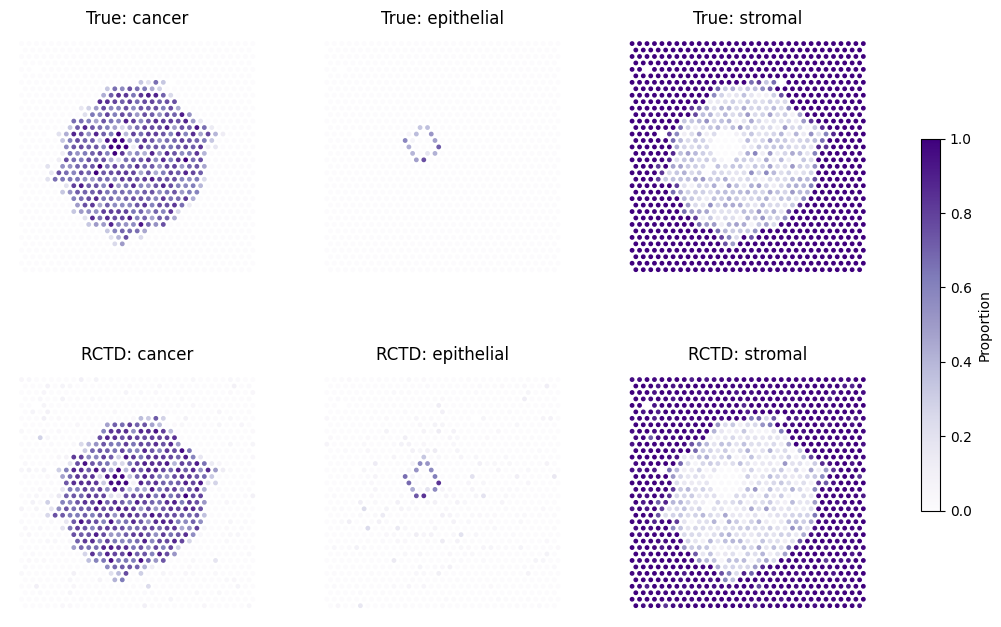

In [9]:
xy = pd.read_csv("visium/outs/spatial/tissue_positions.csv", index_col=0).loc[rctd.index]
fig, axes = plt.subplots(2, len(rctd.columns), figsize=(4 * len(rctd.columns), 8))
for row, (label, values) in enumerate([("True", true_prop), ("RCTD", rctd)]):
    for col, cell_type in enumerate(rctd.columns):
        ax = axes[row, col]
        im = ax.scatter(xy["pxl_col_in_fullres"], xy["pxl_row_in_fullres"], c=values[cell_type], s=6,
                        cmap="Purples", vmin=0, vmax=1)
        ax.set_title(f"{label}: {cell_type}")
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.02, label="Proportion")
plt.show()

RCTD's proportions followed the true ones closely for all three cell types, with Pearson correlations of 0.99 for cancer cells and stromal cells and 0.91 for normal epithelial cells, and mean absolute errors between 0.01 and 0.04.
It overestimated the cancer proportion slightly, at 0.24 against 0.22 on average, and the maps show small epithelial proportions in a few spots without normal epithelial cells.
In principle, we expect normal epithelial cells to be the hardest type, since they are rare in the section and in the reference (48 cells), and cancer cells keep the expression baseline of the normal epithelium from which the tumor arose.
The cell types of the reference here have no annotation errors, so an annotation from a copy-number caller would in principle make cancer cells and normal epithelial cells harder to separate.

## Making the benchmark harder or easier

The number of cells per spot is set by the thickness of the section (`depth_frac` of [`Resection.slice`](https://pedrofale.github.io/iscc/reference/Resection/)) and by the spot size of [`Visium`](https://pedrofale.github.io/iscc/reference/Visium/) (`spot_radius`), and more cells per spot make the mixtures harder to resolve.
Two technical artifacts of Visium, lateral diffusion (`diffusion_sigma`) and spot swapping (`bleed_rate`, `bleed_distal`, `bleed_sigma`), are off by default, and switching them on mixes the counts of neighboring spots, as [Shape the data](03_shape_the_data.ipynb) shows.
The reference here comes from another region of the tumor than the section, and a reference with fewer cells of a type is less representative of the section.
An annotation with errors, for example cancer cells called from copy number, makes the cancer and epithelial profiles less distinct.
A section of another region (`center` of `primary_window`) changes how much of the section is cancer, and the other [pregrown tumors](https://pedrofale.github.io/iscc/reference/#pregrown-tumors), such as `iscc.pregrown.cin`, whose clones differ mostly in copy number, change how much cancer cells differ from normal epithelial cells.